# 05 – Limitations of v0.1 and gradient boosting

**ML Project – Early Detection of Students at Risk of Dropout** · Week 3

Module owner: **Léo Chen** · Group **AALT** (DIA4): Léo Chen, Adam Gaabi, Timéo Brajon, Axel Warot

## Limitations of AutoML v0.1
- **Optimistic score:** the best configuration was chosen and evaluated on the same folds.
- **No boosting:** the models that work best on tabular data in the literature were not tried.
- **Default decision rule:** dropout recall ≈ 0.70, below our 0.80 target.
- **Enrolled class:** F1 ≈ 0.49, it limits macro-F1.
- **Random split only:** we did not check if the model works on a new cohort.

This notebook fixes the first two points: gradient boosting models, all evaluated with **nested cross-validation**.

In [1]:
import sys,json,time,warnings
warnings.filterwarnings("ignore")
sys.path.insert(0,"../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from features import *
from evaluation import *
pd.set_option("display.width",160)
pd.set_option("display.max_columns",40)
tr=pd.read_csv("../data/processed/train.csv")
from scipy.stats import loguniform,randint,uniform
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
s="B_semester1"
X,y=split_xy(tr,s)
y=encode(y)
print(X.shape,np.bincount(y))

(3539, 32) [1137  635 1767]


## Protocol
- Same **outer 5-fold** split (seed 42) for every model of week 3, so the comparison is paired fold by fold.
- Inside each outer training fold: randomised search, 20 configurations × **inner 3-fold**, scored by macro-F1.
- The outer fold is never used for tuning: the outer score is an unbiased estimate of "model + tuning".

In [2]:
def tuned(model,space,n_iter=20):
    return sk(RandomizedSearchCV(Pipeline([("prep",preprocessor(s)),("clf",model)]),space,n_iter=n_iter,scoring="f1_macro",cv=INNER,random_state=SEED,n_jobs=-1,error_score="raise"))
CW=[None,"balanced"]
spaces={
"Random forest":(RandomForestClassifier(random_state=SEED,n_jobs=1),{"clf__n_estimators":randint(200,500),"clf__max_depth":[None,8,12,20],"clf__min_samples_leaf":randint(1,10),"clf__max_features":["sqrt",0.3,0.5],"clf__class_weight":CW+["balanced_subsample"]}),
"HistGradientBoosting":(HistGradientBoostingClassifier(random_state=SEED),{"clf__learning_rate":loguniform(0.02,0.3),"clf__max_leaf_nodes":randint(8,64),"clf__min_samples_leaf":randint(10,80),"clf__l2_regularization":loguniform(1e-3,10),"clf__class_weight":CW}),
"LightGBM":(LGBMClassifier(random_state=SEED,n_jobs=1,verbose=-1),{"clf__n_estimators":randint(100,600),"clf__learning_rate":loguniform(0.01,0.2),"clf__num_leaves":randint(8,64),"clf__min_child_samples":randint(10,80),"clf__subsample":uniform(0.6,0.4),"clf__subsample_freq":[1],"clf__colsample_bytree":uniform(0.5,0.5),"clf__reg_lambda":loguniform(1e-3,10),"clf__class_weight":CW}),
"XGBoost":(XGBClassifier(random_state=SEED,n_jobs=1,tree_method="hist",eval_metric="mlogloss"),{"clf__n_estimators":randint(100,600),"clf__learning_rate":loguniform(0.01,0.2),"clf__max_depth":randint(2,8),"clf__min_child_weight":loguniform(0.5,10),"clf__subsample":uniform(0.6,0.4),"clf__colsample_bytree":uniform(0.5,0.5),"clf__reg_lambda":loguniform(1e-2,10)})}

In [3]:
res=[run_folds(sk(Pipeline([("prep",preprocessor(s)),("clf",LogisticRegression(max_iter=3000,class_weight="balanced"))])),X,y,"Baseline LogReg",s)]
times={}
for name,(m,sp) in spaces.items():
    t=time.perf_counter()
    res.append(run_folds(tuned(m,sp),X,y,name,s))
    times[name]=time.perf_counter()-t
res=pd.concat(res)
res.to_csv("../results/w3_05_boosting_folds.csv",index=False)
summary(res).join(pd.Series(times,name="time (s)"),on="model").round(3)

macro_f1  macro_f1_std  bal_acc  dropout_recall  enrolled_f1  roc_auc_ovr  time (s)
scenario    model                                                                                                    
B_semester1 LightGBM                 0.702         0.025    0.706           0.718        0.513        0.876   116.742
            HistGradientBoosting     0.699         0.018    0.702           0.718        0.503        0.875   190.314
            Random forest            0.688         0.028    0.686           0.715        0.480        0.867   228.378
            Baseline LogReg          0.684         0.022    0.692           0.699        0.488        0.863       NaN
            XGBoost                  0.681         0.035    0.672           0.759        0.423        0.879    98.953

## Paired comparison with the baseline

In [4]:
piv=res.pivot(index="fold",columns="model",values="macro_f1")
diff=piv.sub(piv["Baseline LogReg"],axis=0).drop(columns="Baseline LogReg")
pd.DataFrame({"mean gain":diff.mean(),"std":diff.std(),"folds won (/5)":(diff>0).sum()}).sort_values("mean gain",ascending=False).round(3)

,mean gain,std,folds won (/5)
model,,,
LightGBM,0.018,0.007,5
HistGradientBoosting,0.015,0.018,4
Random forest,0.004,0.007,3
XGBoost,-0.002,0.026,3


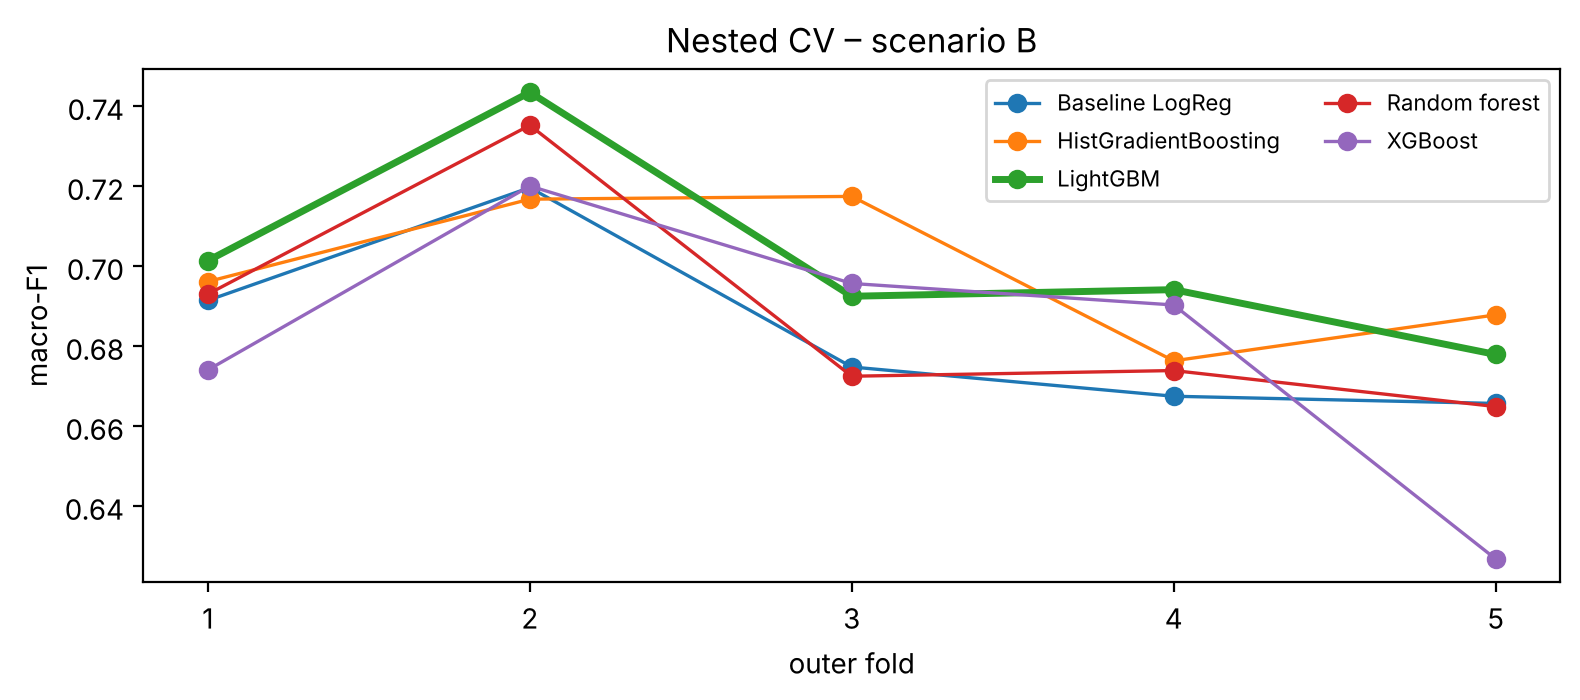

In [5]:
fig,ax=plt.subplots(figsize=(8,3.6))
for c in piv.columns:ax.plot(piv.index+1,piv[c],"o-",label=c,lw=2.5 if c=="LightGBM" else 1.2)
ax.set_xticks(range(1,6));ax.set_xlabel("outer fold");ax.set_ylabel("macro-F1");ax.legend(fontsize=8,ncol=2);ax.set_title("Nested CV – scenario B")
plt.tight_layout();plt.savefig("../report/figures/w3_boosting_folds.png",dpi=150);plt.show()

- **LightGBM** (0.702) and **HistGradientBoosting** (0.699) give the best macro-F1, +0.018 and +0.015 over the baseline; LightGBM beats it on all 5 folds.
- **XGBoost** is lower: it has no `class_weight` option, so it neglects the minority class *Enrolled* (F1 0.42 vs. 0.51 for LightGBM), even if its dropout recall is higher (0.76).
- The gains are of the same order as the fold-to-fold standard deviation (≈ 0.02): boosting helps, but the baseline is already strong on this data.

## Final hyperparameters
Search on the whole training set (same space, 30 configurations): these parameters are reused for the ensembles (notebook 08) and the imbalance study (notebook 06).

In [6]:
best={}
for name in ["Random forest","LightGBM"]:
    m,sp=spaces[name]
    g=RandomizedSearchCV(Pipeline([("prep",preprocessor(s)),("clf",m)]),sp,n_iter=30,scoring="f1_macro",cv=INNER,random_state=SEED,n_jobs=-1,error_score="raise").fit(X,y)
    best[name]={k.replace("clf__",""):(v.item() if hasattr(v,"item") else v) for k,v in g.best_params_.items()}
    print(name,round(g.best_score_,3),best[name])
json.dump(best,open("../results/best_params.json","w"),indent=1)

Random forest 0.687 {'class_weight': 'balanced', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 221}


LightGBM 0.692 {'class_weight': 'balanced', 'colsample_bytree': 0.6061695553391381, 'learning_rate': 0.017240892195821537, 'min_child_samples': 30, 'n_estimators': 260, 'num_leaves': 19, 'reg_lambda': 0.27964859516062457, 'subsample': 0.6028265220878869, 'subsample_freq': 1}
